# NYC Taxi Trips: SQL Analysis
**Author:** *VICTOR CHIGBU*

**Goal:** answer real business questions about 6,433 NYC taxi trips (March 2019) using SQL only: filtering, aggregation, CASE, CTEs, joins, and window functions.

**How it works:** SQL runs on SQLite inside Python. Pandas only loads the data and displays results. Every analysis step is a SQL query.

In [1]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option("display.width", 150)

def q(sql):
    """Run a SQL query and return a DataFrame."""
    return pd.read_sql_query(sql, conn)

## 1. Build the database
Load the raw data into a SQLite table, then split it into a `trips` table and a `zones` lookup table. Splitting repeated text into a lookup table is database normalization, and it gives us something to JOIN.

In [2]:
raw = sns.load_dataset("taxis")
raw["pickup"] = raw["pickup"].astype(str)
raw["dropoff"] = raw["dropoff"].astype(str)

conn = sqlite3.connect(":memory:")
raw.to_sql("raw_trips", conn, index=False)

conn.executescript("""
CREATE TABLE zones AS
SELECT ROW_NUMBER() OVER (ORDER BY pickup_zone) AS zone_id,
       pickup_zone AS zone_name,
       MIN(pickup_borough) AS borough
FROM raw_trips
WHERE pickup_zone IS NOT NULL
GROUP BY pickup_zone;

CREATE TABLE trips AS
SELECT ROW_NUMBER() OVER () AS trip_id,
       r.pickup, r.dropoff, r.passengers, r.distance, r.fare, r.tip,
       r.tolls, r.total, r.color, r.payment,
       z.zone_id AS pickup_zone_id
FROM raw_trips r
LEFT JOIN zones z ON z.zone_name = r.pickup_zone;
""")
q("SELECT COUNT(*) AS trips FROM trips").join(q("SELECT COUNT(*) AS zones FROM zones"))

,trips,zones
0,6433,194


## 2. Check data quality

In [3]:
q("""
SELECT COUNT(*) AS total_trips,
       SUM(payment IS NULL) AS missing_payment,
       SUM(pickup_zone_id IS NULL) AS missing_zone,
       SUM(distance = 0) AS zero_distance,
       MIN(fare) AS min_fare, MAX(fare) AS max_fare
FROM trips
""")

,total_trips,missing_payment,missing_zone,zero_distance,min_fare,max_fare
0,6433,44,26,51,1.0,150.0


**Observation:** Of 6,433 trips, 44 have no payment type and 26 have no pickup zone. 51 trips have a distance of 0, which are probably cancelled or voided rides. I kept the missing-payment trips in the revenue queries and excluded them when comparing payment types. Zone-based queries drop the 26 trips without a zone automatically through the JOIN.

## 3. Q1: How do cash and credit card trips differ?
Cash tips aren't recorded, so tip figures are only meaningful for credit card.

In [4]:
q("""
SELECT payment,
       COUNT(*)                  AS trips,
       ROUND(AVG(fare), 2)       AS avg_fare,
       ROUND(AVG(tip), 2)        AS avg_tip,
       ROUND(AVG(distance), 2)   AS avg_distance
FROM trips
WHERE payment IS NOT NULL
GROUP BY payment
ORDER BY trips DESC
""")

,payment,trips,avg_fare,avg_tip,avg_distance
0,credit card,4577,13.69,2.78,3.22
1,cash,1812,11.59,0.00,2.54


## 4. Q2: Which pickup boroughs earn the most?

In [5]:
q("""
SELECT z.borough,
       COUNT(*)                    AS trips,
       ROUND(SUM(t.total), 0)      AS revenue,
       ROUND(AVG(t.total), 2)      AS avg_total
FROM trips t
JOIN zones z ON z.zone_id = t.pickup_zone_id
GROUP BY z.borough
ORDER BY revenue DESC
""")

,borough,trips,revenue,avg_total
0,Manhattan,5268,87820.0,16.67
1,Queens,657,20801.0,31.66
2,Brooklyn,383,7367.0,19.24
3,Bronx,99,2254.0,22.77


## 5. Q3: What time of day is busiest? (`strftime` + `CASE`)

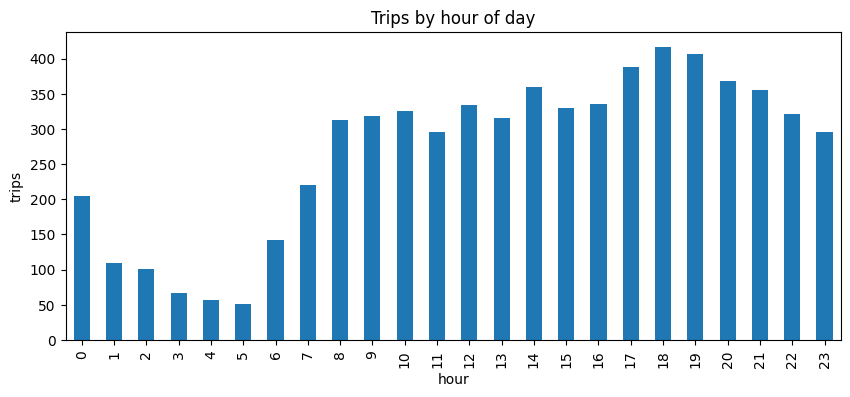

In [6]:
by_hour = q("""
SELECT CAST(strftime('%H', pickup) AS INTEGER) AS hour,
       COUNT(*)                                AS trips,
       ROUND(AVG(fare), 2)                     AS avg_fare
FROM trips
GROUP BY hour
ORDER BY hour
""")
by_hour.plot(x="hour", y="trips", kind="bar", legend=False, figsize=(10,4), title="Trips by hour of day")
plt.ylabel("trips"); plt.show()

In [7]:
q("""
SELECT CASE
         WHEN CAST(strftime('%H', pickup) AS INTEGER) BETWEEN 6  AND 9  THEN '1 Morning rush'
         WHEN CAST(strftime('%H', pickup) AS INTEGER) BETWEEN 10 AND 15 THEN '2 Midday'
         WHEN CAST(strftime('%H', pickup) AS INTEGER) BETWEEN 16 AND 19 THEN '3 Evening rush'
         ELSE '4 Night'
       END AS period,
       COUNT(*) AS trips,
       ROUND(AVG(fare), 2) AS avg_fare
FROM trips
GROUP BY period
ORDER BY period
""")

,period,trips,avg_fare
0,1 Morning rush,995,12.78
1,2 Midday,1960,13.32
2,3 Evening rush,1547,13.20
3,4 Night,1931,12.94


## 6. Q4: Which pickup zones have the highest tip percentage? (CTE + HAVING)
Only credit card trips, and only zones with at least 20 trips so one lucky ride doesn't dominate.

In [8]:
q("""
WITH card_trips AS (
    SELECT * FROM trips
    WHERE payment = 'credit card' AND fare > 0
)
SELECT z.zone_name, z.borough,
       COUNT(*) AS trips,
       ROUND(100.0 * SUM(c.tip) / SUM(c.fare), 1) AS tip_pct
FROM card_trips c
JOIN zones z ON z.zone_id = c.pickup_zone_id
GROUP BY z.zone_id
HAVING COUNT(*) >= 20
ORDER BY tip_pct DESC
LIMIT 10
""")

,zone_name,borough,trips,tip_pct
0,Greenwich Village South,Manhattan,59,27.6
1,Central Park,Manhattan,54,26.7
2,Greenwich Village North,Manhattan,71,26.5
3,West Village,Manhattan,84,26.3
4,Upper East Side South,Manhattan,151,26.3
5,Upper East Side North,Manhattan,133,26.0
6,Meatpacking/West Village West,Manhattan,44,25.8
7,Midtown East,Manhattan,157,25.6
8,Lenox Hill West,Manhattan,90,25.2
9,Sutton Place/Turtle Bay North,Manhattan,85,25.1


## 7. Q5: Top 3 busiest zones inside each borough (window function `RANK`)

In [9]:
q("""
WITH zone_counts AS (
    SELECT z.borough, z.zone_name, COUNT(*) AS trips
    FROM trips t JOIN zones z ON z.zone_id = t.pickup_zone_id
    GROUP BY z.zone_id
),
ranked AS (
    SELECT *, RANK() OVER (PARTITION BY borough ORDER BY trips DESC) AS rnk
    FROM zone_counts
)
SELECT borough, rnk, zone_name, trips
FROM ranked
WHERE rnk <= 3
ORDER BY borough, rnk
""")

,borough,rnk,zone_name,trips
0,Bronx,1,East Concourse/Concourse Village,9
1,Bronx,2,Mott Haven/Port Morris,8
2,Bronx,2,Parkchester,8
3,Brooklyn,1,Fort Greene,39
4,Brooklyn,2,Downtown Brooklyn/MetroTech,37
5,Brooklyn,3,Brooklyn Heights,34
6,Manhattan,1,Midtown Center,230
7,Manhattan,2,Upper East Side South,211
8,Manhattan,3,Penn Station/Madison Sq West,210
9,Queens,1,JFK Airport,151


## 8. Q6: Daily revenue with a running total (window function `SUM() OVER`)
Heads up: the first row (Feb 28) has a single stray trip. Why might that be, and should you filter it out?

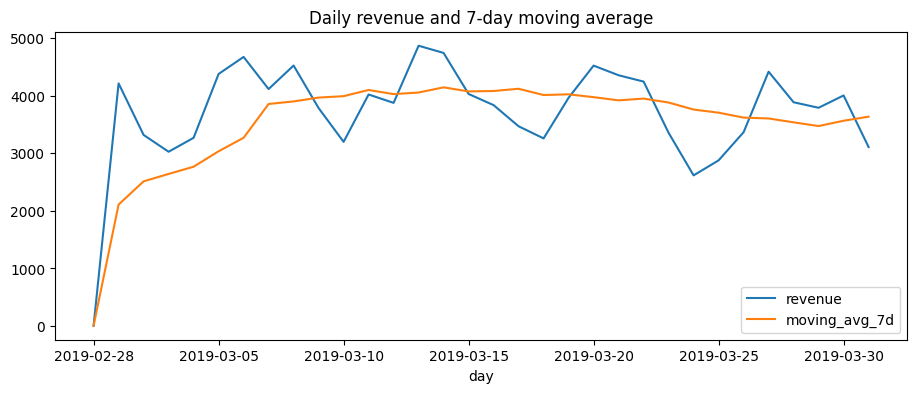

,day,revenue,running_total,moving_avg_7d
0,2019-02-28,6.30,6.30,6.30
1,2019-03-01,4213.83,4220.13,2110.07
2,2019-03-02,3319.02,7539.15,2513.05
3,2019-03-03,3027.32,10566.47,2641.62
4,2019-03-04,3269.08,13835.55,2767.11


In [10]:
daily = q("""
WITH d AS (
    SELECT DATE(pickup) AS day, ROUND(SUM(total), 2) AS revenue
    FROM trips
    GROUP BY day
)
SELECT day, revenue,
       ROUND(SUM(revenue) OVER (ORDER BY day), 2) AS running_total,
       ROUND(AVG(revenue) OVER (ORDER BY day ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 2) AS moving_avg_7d
FROM d
ORDER BY day
""")
daily.plot(x="day", y=["revenue", "moving_avg_7d"], figsize=(11,4), title="Daily revenue and 7-day moving average")
plt.show()
daily.head()

## 9. Your own questions
Write **three more SQL questions** that interest you and answer them. Ideas: do longer trips get a lower price per mile? Are yellow and green taxis used differently? Do larger groups tip more? Which weekday is busiest (`strftime('%w', pickup)`)?

In [11]:
# Question 1: write your SQL between the triple quotes, then delete the # in front of the next line
# q("""SELECT ... """)

## 10. Conclusions
- **Card vs cash:** 4,577 trips were paid by credit card and 1,812 by cash. Card trips were longer (3.22 vs 2.54 miles on average) and had a higher average fare ($13.69 vs $11.59). Cash tips are not recorded, so the $0.00 average cash tip reflects missing data, not stingy riders. Across all credit card trips, tips were about 20% of the fare.
- **Where the money is:** Manhattan generated the most revenue by far ($87.8k from 5,268 trips), but Queens has the highest average total ($31.66 vs $16.67 in Manhattan). The reason is the airports. JFK and LaGuardia are the top two Queens pickup zones, and their trips are long (about 7.5 miles on average vs 2.4 in Manhattan).
- **When it's busy:** Demand peaks in the evening, with 6 pm the busiest hour (417 trips) and 5 pm to 8 pm all near the top, and bottoms out between 3 and 5 am. Average fare barely changes by time of day (about $12.78 to $13.32), so busy periods mean more trips, not pricier ones.
- **Tipping:** The highest tip percentages (about 25 to 28%) were in Manhattan neighbourhoods such as Greenwich Village, the Upper East Side and the West Village, among zones with at least 20 trips.
- **Limitations:** The data covers a single month (March 2019) and only 6,433 trips, a small sample of all NYC taxis. Many zones have fewer than 10 trips, so zone rankings outside Manhattan are noisy. Cash tips are missing, and a few records (zero distance, a stray Feb 28 trip) look like data errors.
- **What I'd analyze next:** Weekday vs weekend demand, fare per mile by distance, and whether the airport premium holds across months with a larger dataset.